# Analysis of the output

In [254]:
import pandas as pd

#df = pd.read_excel('./programmer_conversation_llama32_llama32_complete.xlsx', sheet_name='Sheet1')
#df = pd.read_excel('./programmer_conversation_llama32_deepseek3.xlsx', sheet_name='Sheet1')
df = pd.read_excel('./programmer_conversation_gemma3_minicp.xlsx', sheet_name='Sheet1')
df = df[~df['content'].str.contains(r'^\*+$')]

In [255]:
# select only the rows with role "assistant" and make them into a list
assistant_rows = df[df['role'] == 'assistant']
assistant_rows = assistant_rows[['content']].reset_index(drop=True)
assistant_rows = assistant_rows['content'].tolist()

In [256]:
len(assistant_rows)

8

In [257]:
# for each of the row, calculate BLUE score to the previous one
def calculate_bleu_score(reference, candidate):
    from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
    reference_tokens = reference.split()
    candidate_tokens = candidate.split()
    smoothing = SmoothingFunction().method1
    return sentence_bleu([reference_tokens], candidate_tokens, smoothing_function=smoothing)
bleu_scores = []

for i in range(1, len(assistant_rows)):
    reference = assistant_rows[i-1]
    candidate = assistant_rows[i]
    bleu_score = calculate_bleu_score(reference, candidate)
    bleu_scores.append(bleu_score)

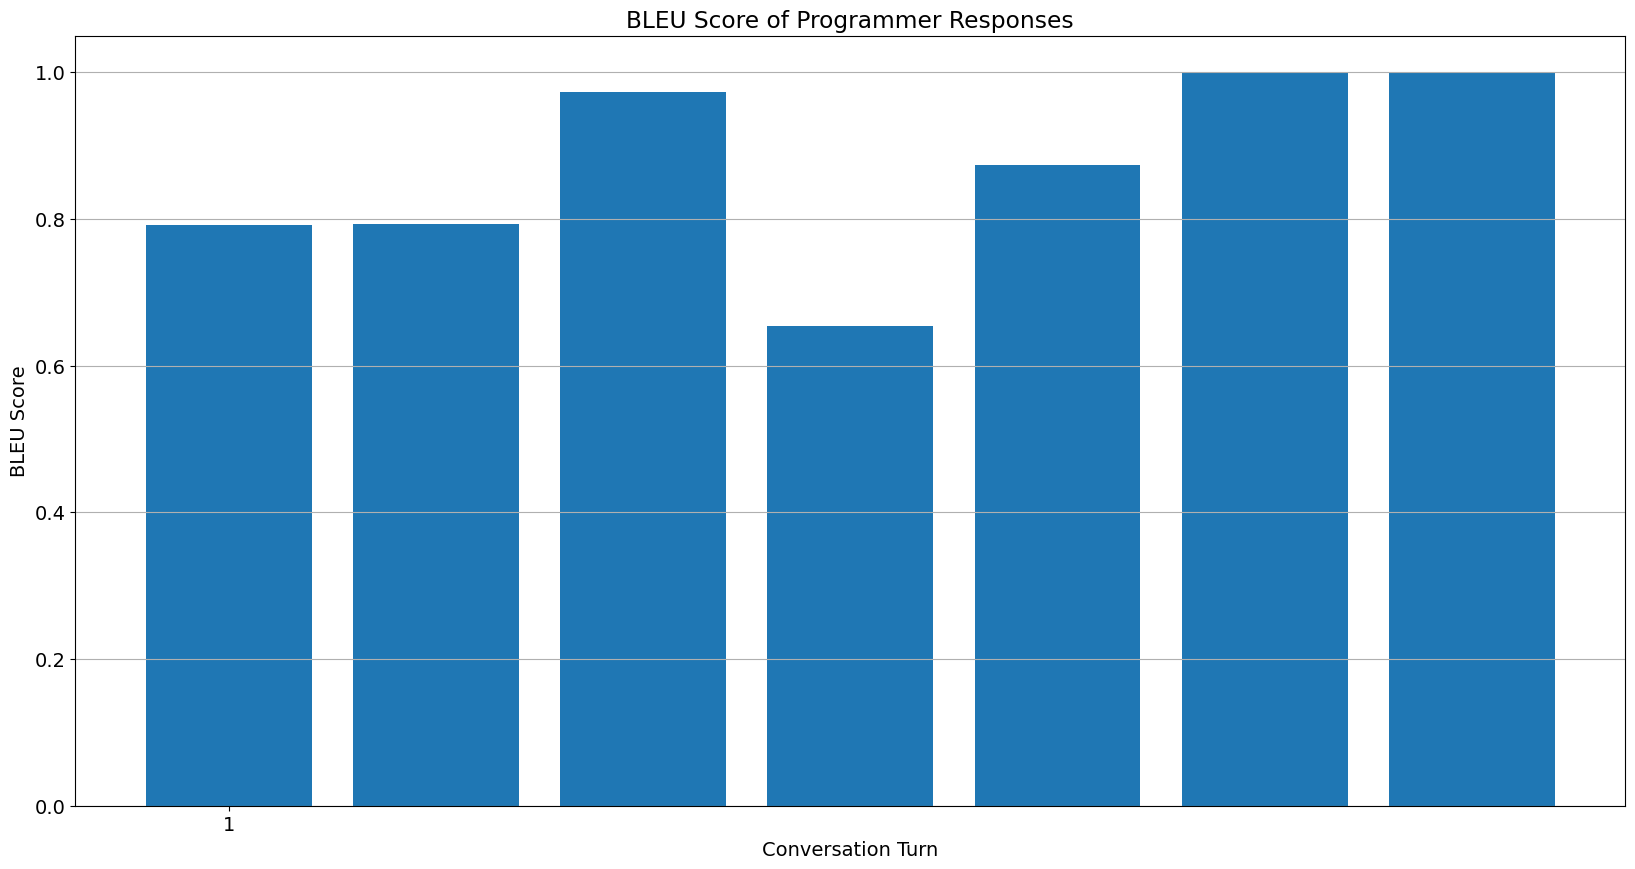

In [258]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 14})

plt.figure(figsize=(20, 10))
plt.bar(range(len(bleu_scores)), bleu_scores)
plt.xlabel('Conversation Turn')
plt.ylabel('BLEU Score')
plt.title('BLEU Score of Programmer Responses')
tick_positions = list(range(0, len(bleu_scores), 50))
tick_labels = [str(i+1) for i in tick_positions]
plt.xticks(tick_positions, tick_labels)
plt.grid(axis='y')
plt.show()

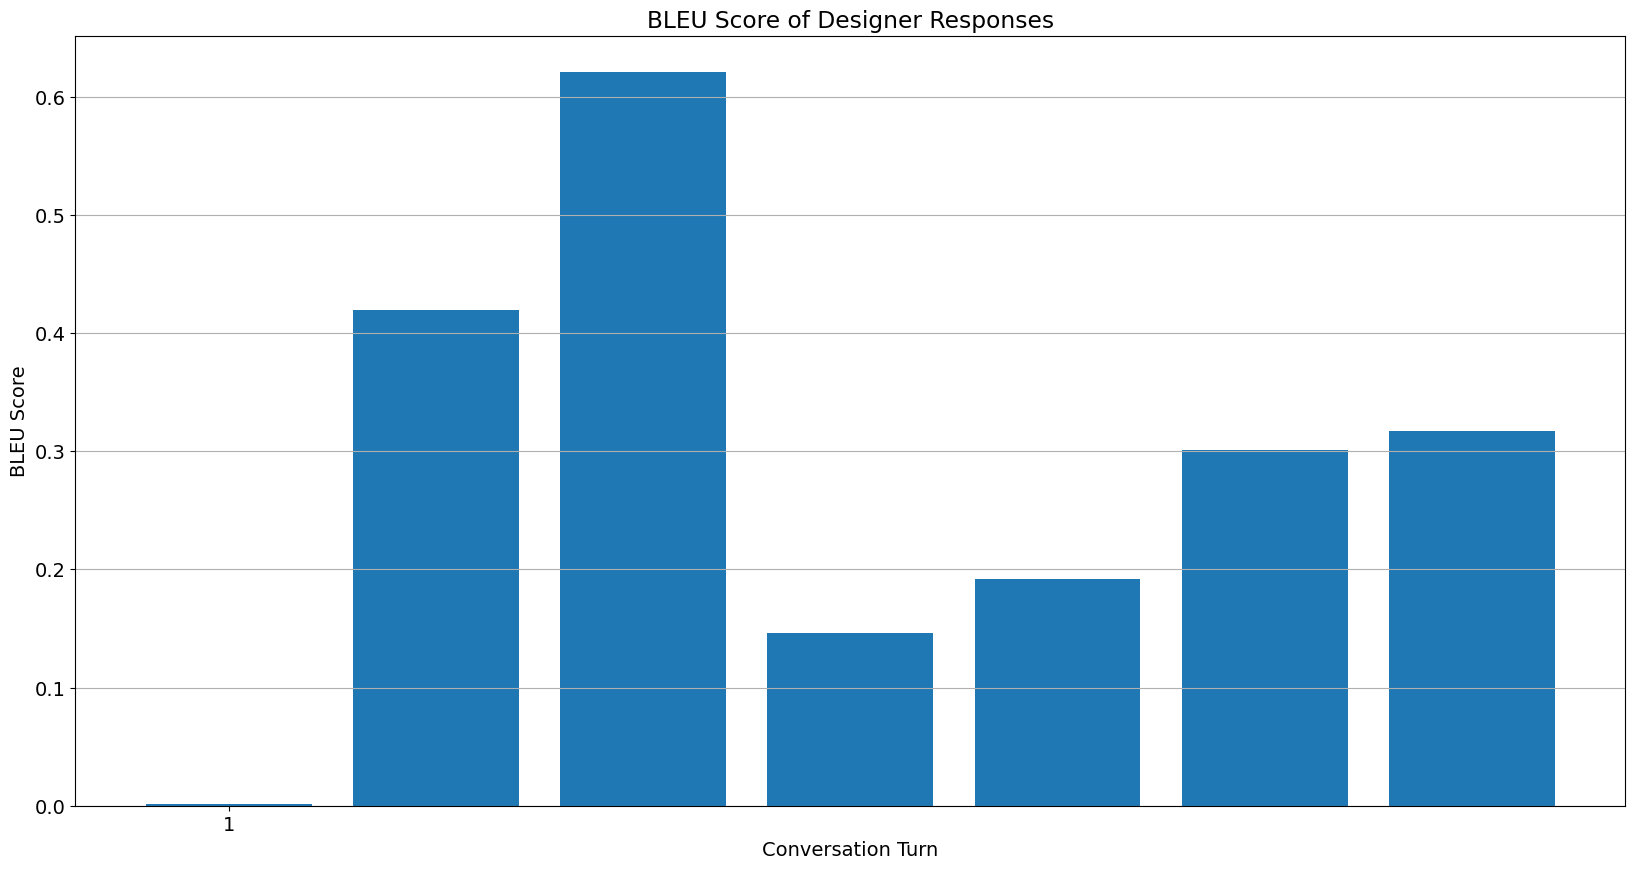

In [259]:
# now do the same for rows with role "user"
# remove rows that contain only "*" in the content column
user_rows = df[df['role'] == 'user']
user_rows = user_rows[['content']].reset_index(drop=True)
user_rows = user_rows['content'].tolist()

len(user_rows)

# for each of the row, calculate BLUE score to the previous one
bleu_scores = []
for i in range(1, len(user_rows)):
    reference = user_rows[i-1]
    candidate = user_rows[i]
    bleu_score = calculate_bleu_score(reference, candidate)
    bleu_scores.append(bleu_score)

plt.rcParams.update({'font.size': 14})

plt.figure(figsize=(20, 10))
plt.bar(range(len(bleu_scores)), bleu_scores)
plt.xlabel('Conversation Turn')
plt.ylabel('BLEU Score')
plt.title('BLEU Score of Designer Responses')
tick_positions = list(range(0, len(bleu_scores), 50))
tick_labels = [str(i+1) for i in tick_positions]
plt.xticks(tick_positions, tick_labels)
plt.grid(axis='y')
plt.show()